In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Thêm thư mục gốc vào sys.path để import module từ src/
sys.path.append("..")
from src.rfm import RFMProcessor

# 2. Cấu hình các đường dẫn thư mục lưu trữ
BASE_DIR = Path("..")
paths = {
    "processed": BASE_DIR / "data" / "processed",
    "figures": BASE_DIR / "reports" / "figures",
    "tables": BASE_DIR / "reports" / "tables",
}

# Tự động tạo các thư mục nếu chưa tồn tại
for p in paths.values():
    p.mkdir(parents=True, exist_ok=True)

# 3. Đọc dữ liệu đã làm sạch từ data/processed/
cleaned_file_path = paths["processed"] / "olist_cleaned_dataset.csv"
print(f"Đang đọc dữ liệu từ: {cleaned_file_path.resolve()}")
df_clean = pd.read_csv(cleaned_file_path)
df_clean["order_purchase_timestamp"] = pd.to_datetime(
    df_clean["order_purchase_timestamp"]
)

# 4. Gọi hàm từ src/rfm.py để tính toán chỉ số RFM thô
rfm_processor = RFMProcessor(df_clean)
rfm_df = rfm_processor.compute_rfm()

Đang đọc dữ liệu từ: D:\Machine Learning\PROJECT REPO\data\processed\olist_cleaned_dataset.csv
 Đã tính RFM thô cho 93,357 khách hàng duy nhất.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def perform_eda(rfm_df: pd.DataFrame, paths: dict):
    """Thực hiện EDA tập trung vào ba chỉ số R, F, M, hiển thị và lưu biểu đồ/bảng biểu."""
    print("=" * 70)
    print("GIAI ĐOẠN EDA: PHÂN TÍCH KHÁM PHÁ CÁC CHỈ SỐ R, F, M")
    print("=" * 70)

    # 1. THỐNG KÊ MÔ TẢ
    desc = rfm_df[["Recency", "Frequency", "Monetary"]].describe().T
    print("\n[1] Thống kê mô tả R, F, M:")
    print(desc.to_string())

    table_path = paths["tables"] / "rfm_descriptive_stats.csv"
    desc.to_csv(table_path)
    print(f"\n[OK] Đã lưu bảng thống kê mô tả -> {table_path}")

    sns.set_theme(style="whitegrid")
    cols = ["Recency", "Frequency", "Monetary"]
    colors = ["skyblue", "salmon", "lightgreen"]

    # ==========================================
    # 2. PHÂN TÍCH ĐƠN BIẾN (UNIVARIATE)
    # ==========================================

    # 2.1 Histogram (Phân phối)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for i, col in enumerate(cols):
        sns.histplot(rfm_df[col], kde=True, ax=axes[i], color=colors[i], bins=30)
        axes[i].set_title(f"Phân phối của {col}", fontsize=12, fontweight="bold")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Mật độ / Tần suất")

        if col == "Monetary":
            axes[i].set_xlim(left=0, right=rfm_df["Monetary"].quantile(0.95))
        if col == "Frequency":
            axes[i].set_xlim(left=0, right=rfm_df["Frequency"].quantile(0.99))

    plt.tight_layout()
    fig_path_hist = paths["figures"] / "rfm_distribution_histograms.png"
    plt.savefig(fig_path_hist, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"[OK] Đã lưu biểu đồ Histogram -> {fig_path_hist}")

    # 2.2 Boxplot (Tìm Outliers)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for i, col in enumerate(cols):
        sns.boxplot(y=rfm_df[col], ax=axes[i], color=colors[i])
        axes[i].set_title(
            f"Boxplot của {col} (Ngoại lai)", fontsize=12, fontweight="bold"
        )
        axes[i].set_ylabel(col)

    plt.tight_layout()
    fig_path_box = paths["figures"] / "rfm_outliers_boxplots.png"
    plt.savefig(fig_path_box, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"[OK] Đã lưu biểu đồ Boxplot -> {fig_path_box}")

    # ==========================================
    # 3. PHÂN TÍCH ĐA BIẾN (MULTIVARIATE)
    # ==========================================

    # 3.1 Ma trận tương quan Pearson
    plt.figure(figsize=(7, 5))
    corr = rfm_df[["Recency", "Frequency", "Monetary"]].corr()
    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5,
        vmin=-1,
        vmax=1,
    )
    plt.title(
        "Ma trận tương quan Pearson các đặc trưng RFM", fontsize=14, fontweight="bold"
    )
    plt.tight_layout()
    fig_path_corr = paths["figures"] / "rfm_correlation_matrix.png"
    plt.savefig(fig_path_corr, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"[OK] Đã lưu ma trận tương quan Pearson -> {fig_path_corr}")

    # 3.1.2 Ma trận tương quan Spearman
    print("\n[3.1.2] Ma trận tương quan Spearman:")

    rfm_data = rfm_df[['Recency', 'Frequency', 'Monetary']]
    corr_spearman = rfm_data.corr(method='spearman')

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        corr_spearman,
        annot=True,
        cmap='coolwarm',
        fmt=".2f",
        linewidths=0.5,
        vmin=-1,
        vmax=1,
        center=0
    )
    plt.title(
        'Ma trận tương quan Spearman của RFM',
        fontsize=14,
        fontweight='bold'
    )
    plt.tight_layout()

    fig_path_spearman = paths["figures"] / "rfm_spearman_correlation.png"
    plt.savefig(fig_path_spearman, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"[OK] Đã lưu biểu đồ Spearman -> {fig_path_spearman}")

    # 3.2 Biểu đồ phân tán (Pairplot)
    pair_plot = sns.pairplot(
        rfm_df[["Recency", "Frequency", "Monetary"]],
        diag_kind="kde",
        corner=True,
        plot_kws={"alpha": 0.5, "color": "purple"},
    )
    pair_plot.fig.suptitle(
        "Biểu đồ tán xạ (Scatter/Pairplot) giữa R, F, M",
        y=1.02,
        fontsize=14,
        fontweight="bold",
    )
    fig_path_scatter = paths["figures"] / "rfm_scatter_pairplot.png"
    pair_plot.savefig(fig_path_scatter, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"[OK] Đã lưu biểu đồ tán xạ đa biến -> {fig_path_scatter}")

GIAI ĐOẠN EDA: PHÂN TÍCH KHÁM PHÁ CÁC CHỈ SỐ R, F, M

[1] Thống kê mô tả R, F, M:
             count        mean         std   min     25%     50%     75%       max
Recency    93357.0  237.936673  152.584315  1.00  114.00  219.00  346.00    695.00
Frequency  93357.0    1.033420    0.209099  1.00    1.00    1.00    1.00     15.00
Monetary   93357.0  165.198772  226.314579  9.59   63.06  107.78  182.56  13664.08

[OK] Đã lưu bảng thống kê mô tả -> ..\reports\tables\rfm_descriptive_stats.csv


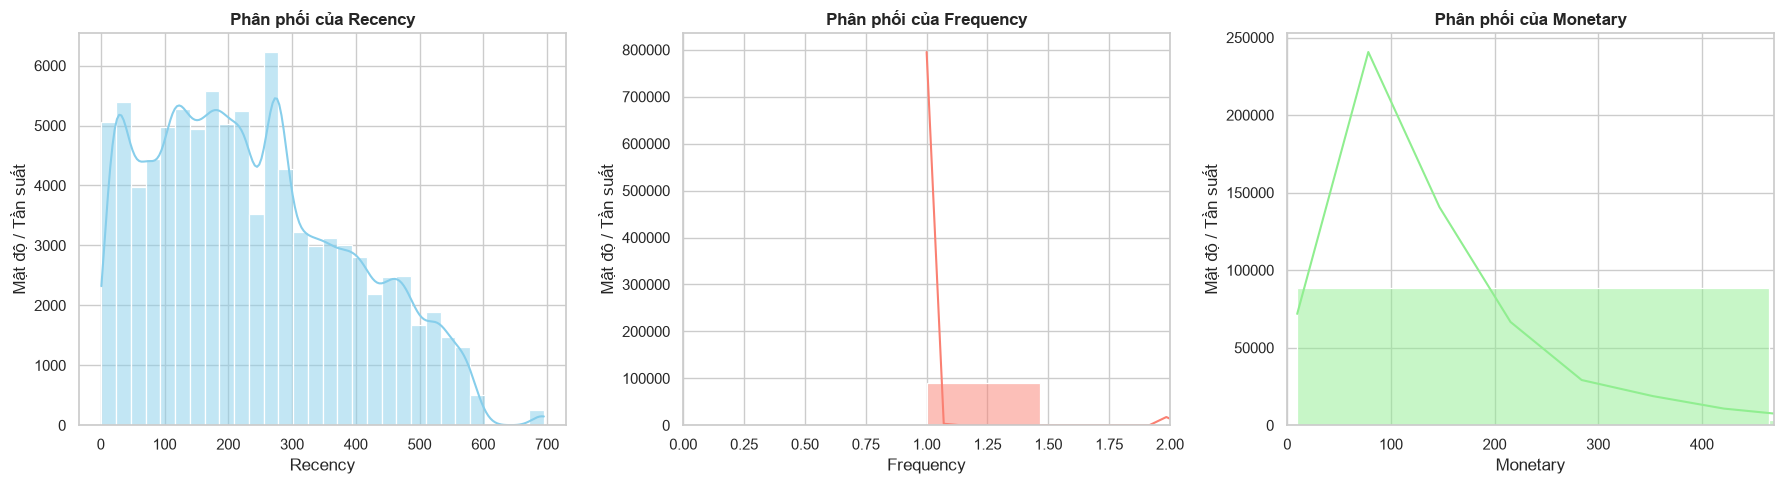

[OK] Đã lưu biểu đồ Histogram -> ..\reports\figures\rfm_distribution_histograms.png


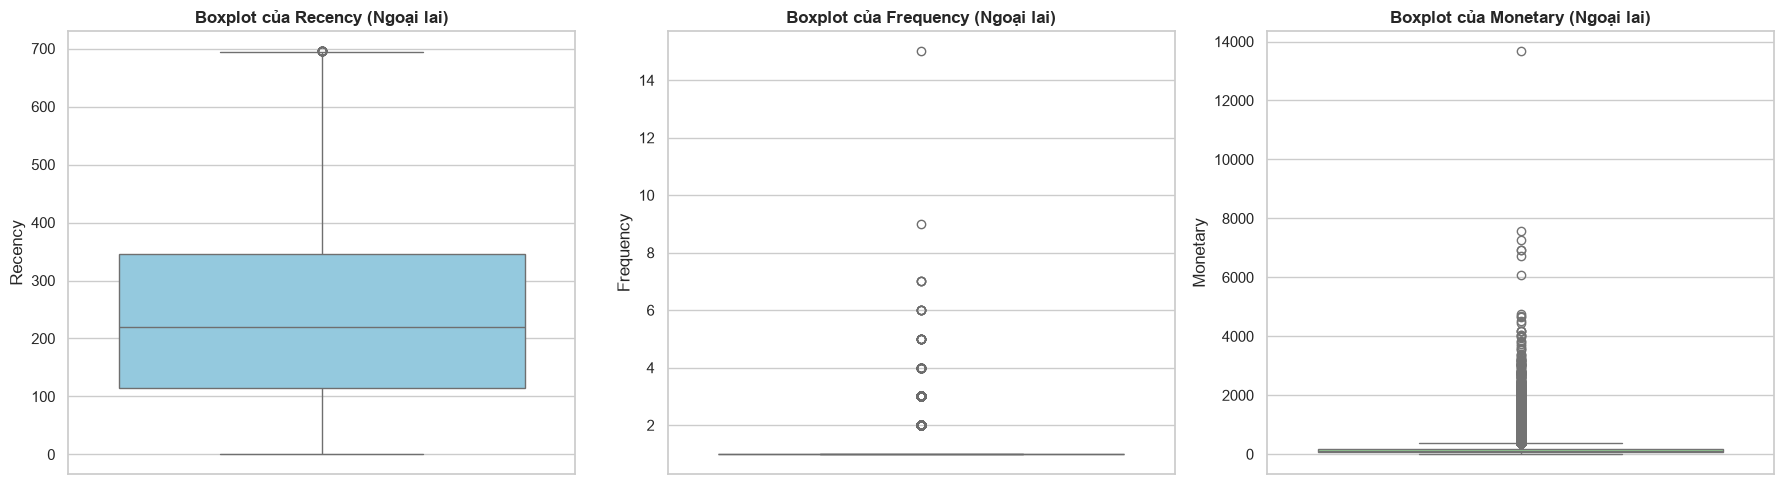

[OK] Đã lưu biểu đồ Boxplot -> ..\reports\figures\rfm_outliers_boxplots.png


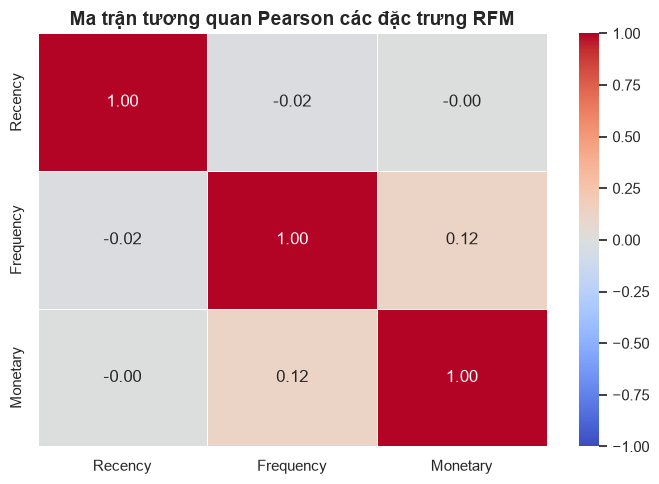

[OK] Đã lưu ma trận tương quan Pearson -> ..\reports\figures\rfm_correlation_matrix.png

[3.1.2] Ma trận tương quan Spearman:


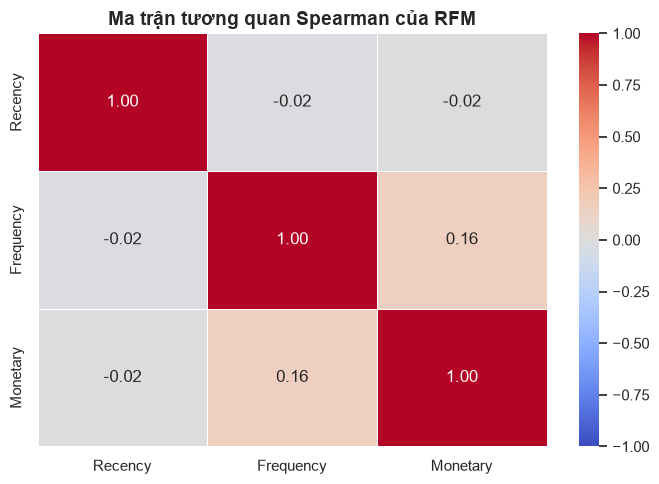

[OK] Đã lưu biểu đồ Spearman -> ..\reports\figures\rfm_spearman_correlation.png


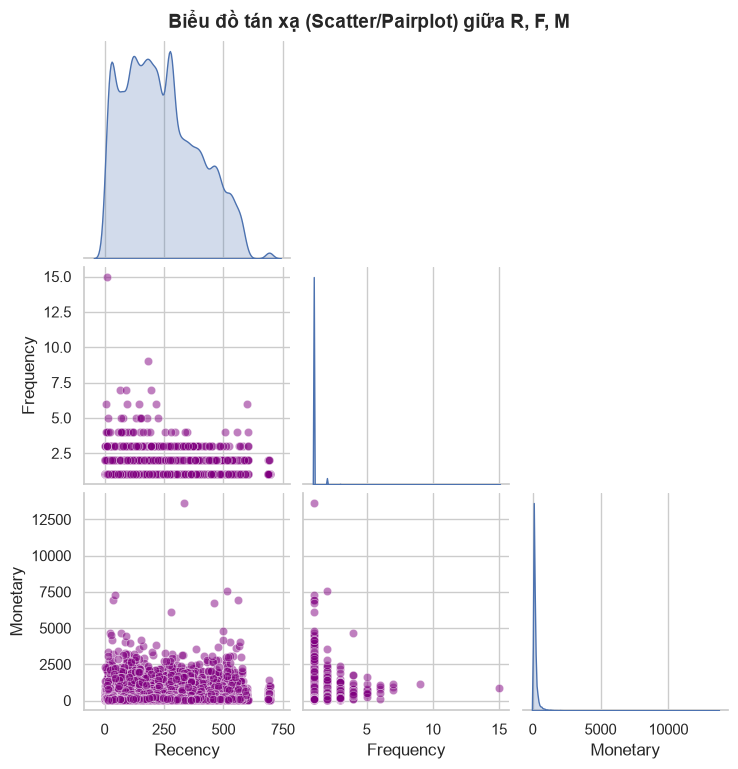

[OK] Đã lưu biểu đồ tán xạ đa biến -> ..\reports\figures\rfm_scatter_pairplot.png


In [8]:
perform_eda(rfm_df, paths)